## Spectral analysis of V462 Lup
This is a draft of the analysis the we need to make (only opening and plotting the spectra). 

Eventually S/N, P Cygni profiles, separation of bands for LC, and 
time of decay by 2 and 3 magnitudes need to be done. Furthermore, more spectral data for the subsequent evolution after eruption is needed to study the system and the novae phenomena itself.

In [1]:
import matplotlib.pyplot as plt 
import pandas as pd
import glob
import os

In [2]:
def open_spec(spec):
    data= pd.read_csv(spec, sep=r'\s+',
                     names= ['wavelength', 'flux', 'var']) 
    wave= data['wavelength']
    flux= data['flux']
    var= data['var']
    
    return  {
            'filename': os.path.basename(spec),
            'wave': wave,
            'flux':flux,
            'var':var
             }
            
search_pattern = os.path.join(r"C:\Users\paisa\OneDrive\Desktop\Proyectos\Proyecto Novas\nova_spects", "*.txt") 
    
    #Lista con todos los archivos que coincidan con *.txt
archivos = glob.glob(search_pattern)
db= []
for spec in archivos:
    dat= open_spec(spec)
    db.append(dat)

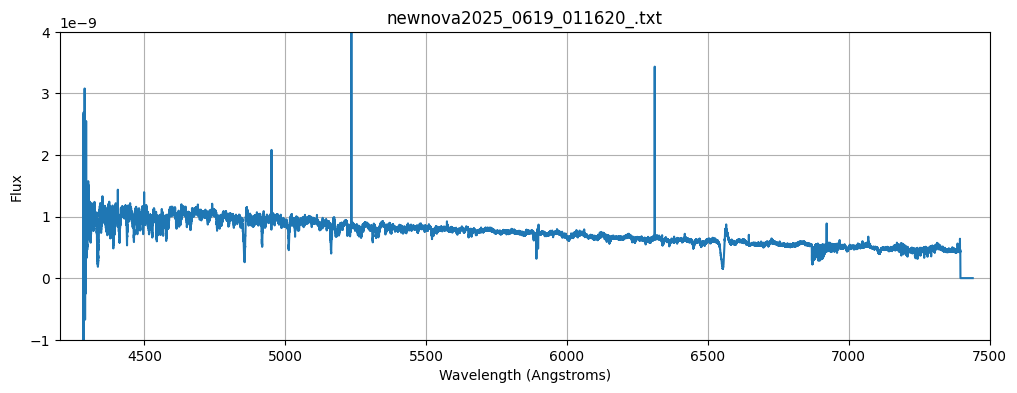

In [3]:
plt.figure(figsize=(12,4))
plt.title(db[1]['filename'])
plt.plot(db[1]['wave'], db[1]['flux'])
plt.xlabel('Wavelength (Angstroms)')
plt.ylabel('Flux')
plt.xlim(4200,7500)
plt.ylim(-0.1*1E-8,0.4*1E-8)
plt.grid('on')
plt.show()

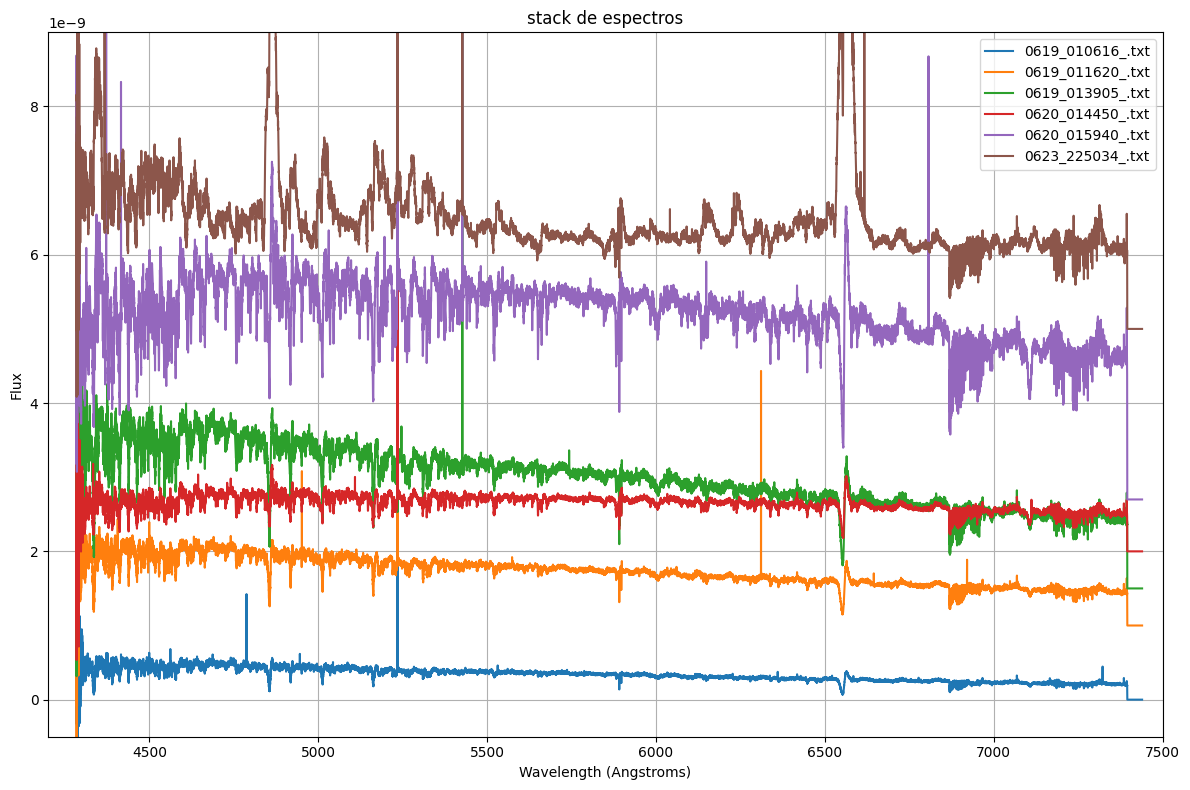

In [4]:
shift= 0.1*1E-8

plt.figure(figsize=(12,8))
plt.title('stack de espectros')
plt.plot(db[0]['wave'], db[0]['flux'],label= db[0]['filename'][12:])
plt.plot(db[1]['wave'], db[1]['flux']+shift,  label= db[1]['filename'][12:] )
plt.plot(db[2]['wave'], db[2]['flux']+shift*1.5, label= db[2]['filename'][12:])
plt.plot(db[3]['wave'], db[3]['flux']+shift*2,  label= db[3]['filename'][12:])
plt.plot(db[4]['wave'], db[4]['flux']+shift*2.7, label= db[4]['filename'][12:])
plt.plot(db[5]['wave'], db[5]['flux'] +shift*5, label= db[5]['filename'][12:])
plt.xlabel('Wavelength (Angstroms)')
plt.ylabel('Flux')
plt.xlim(4200,7500)
plt.ylim(-0.05*1E-8,0.9*1E-8)
plt.tight_layout()
plt.legend()
plt.grid('on')
plt.show()

In [5]:
for i in range(len(db)):
    print(db[i]['filename'][12:23])

0619_010616
0619_011620
0619_013905
0620_014450
0620_015940
0623_225034
0623_233121
0624_022501
0704_003926
0704_005051
0704_010334
0704_011506
0704_012542
0704_013614
0704_014650
0704_015742
0704_020819
0704_021849
0704_022916
0704_024117
0704_025155
0704_030405
0704_031459
0708_010023
0708_012116
0710_235129
0711_003258
0711_005349
0718_003910


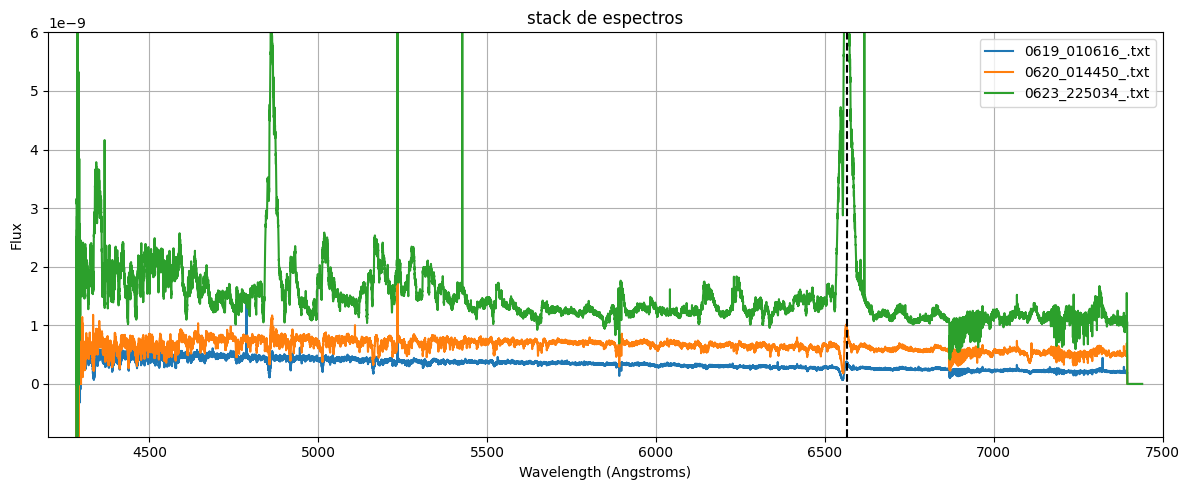

In [6]:
shift= 0.1*1E-8

plt.figure(figsize=(12,5))
plt.title('stack de espectros')
plt.plot(db[0]['wave'], db[0]['flux'],label= db[0]['filename'][12:])
#plt.plot(db[1]['wave'], db[1]['flux'], label= db[1]['filename'][12:] )
#plt.plot(db[2]['wave'], db[2]['flux'], label= db[2]['filename'][12:])
plt.plot(db[3]['wave'], db[3]['flux'],  label= db[3]['filename'][12:])
#plt.plot(db[4]['wave'], db[4]['flux'], label= db[4]['filename'][12:])
plt.plot(db[5]['wave'], db[5]['flux'], label= db[5]['filename'][12:])
plt.axvline(6564.5377, ls='dashed',color='black')
plt.xlabel('Wavelength (Angstroms)')
plt.ylabel('Flux')
plt.xlim(4200,7500)
plt.ylim(-0.09*1E-8,0.6*1E-8)
plt.tight_layout()
plt.legend()
plt.grid('on')
plt.show()

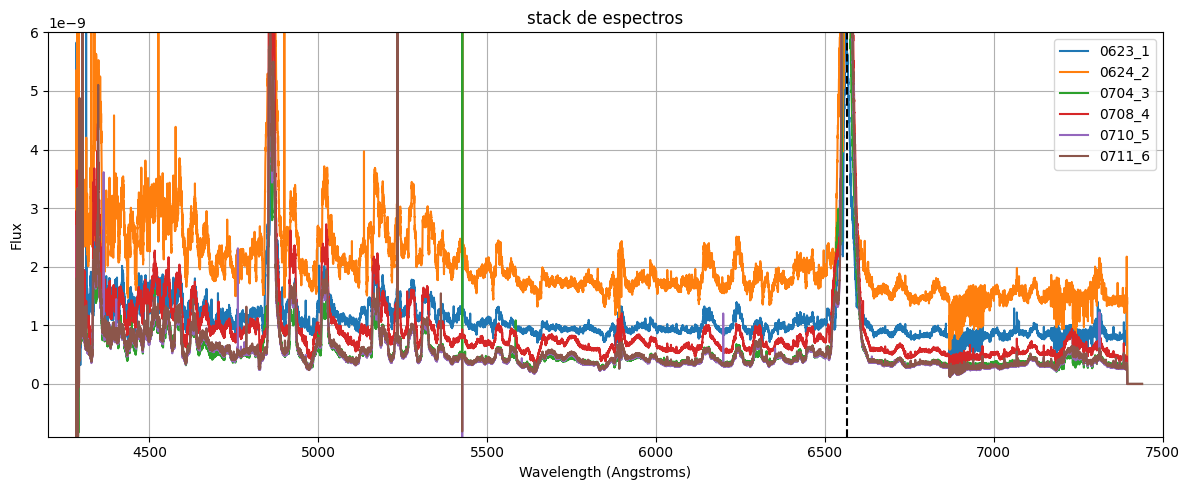

In [7]:
plt.figure(figsize=(12,5))
plt.title('stack de espectros')
plt.plot(db[6]['wave'], db[6]['flux'], label= db[6]['filename'][12:17]+'1') # 06/23
plt.plot(db[7]['wave'], db[7]['flux'], label= db[7]['filename'][12:17]+'2' ) #06/24
plt.plot(db[8]['wave'], db[8]['flux'], label= db[8]['filename'][12:17]+'3') #07//04 hasta el db[22]
plt.plot(db[23]['wave'], db[23]['flux'],  label= db[23]['filename'][12:17]+'4') #07/08 hasta el db[24]
plt.plot(db[25]['wave'], db[25]['flux'], label= db[25]['filename'][12:17]+'5') #07/10 hasta el db[25] (sólo uno ese día)
plt.plot(db[26]['wave'], db[26]['flux'], label= db[26]['filename'][12:17]+'6') #07/11 hasta el db[27]

plt.axvline(6564.5377, ls='dashed',color='black')
plt.xlabel('Wavelength (Angstroms)')
plt.ylabel('Flux')
plt.xlim(4200,7500)
plt.ylim(-0.09*1E-8,0.6*1E-8)
plt.tight_layout()
plt.legend()
plt.grid('on')
plt.show()

In [8]:
LC= pd.read_csv('aavsodata_6ab68962178b5.txt')
LC["JD"]=  pd.to_numeric(LC['JD'],errors="coerce")   #coerce es para transformar en nan todo lo raro
LC["Magnitude"]= pd.to_numeric(LC['Magnitude'],errors="coerce")
LC = LC.dropna(subset=["JD", "Magnitude"])



In [9]:
LC

,JD,Magnitude,Uncertainty,HQuncertainty,Band,Observer Code,Comment Code(s),Comp Star 1,Comp Star 2,Charts,...,Cmag,Kmag,HJD,Star Name,Observer Affiliation,Measurement Method,Grouping Method,ADS Reference,Digitizer,Credit
0,2.460841e+06,7.900,NaN,NaN,Vis.,HLAA,BWLK,HD133971,HD133321,NaN,...,NaN,NaN,NaN,ASASSN-25cm,AAVSO,STD,NaN,NaN,NaN,NaN
1,2.460841e+06,7.800,NaN,NaN,Vis.,HLAA,BUWLV,77,75,X40333G,...,NaN,NaN,NaN,ASASSN-25cm,AAVSO,STD,NaN,NaN,NaN,NaN
2,2.460841e+06,7.700,NaN,NaN,Vis.,CMQ,NaN,77,NaN,X40333G,...,NaN,NaN,NaN,V462 Lup,NaN,STD,NaN,NaN,NaN,NaN
3,2.460841e+06,8.267,0.003,NaN,TB,PEX,NaN,000-BQF-453,000-BQF-455,X40333HG,...,-13.425,-12.807,NaN,ASASSN-25CM,AAVSO,STD,NaN,NaN,NaN,NaN
4,2.460841e+06,8.320,0.003,NaN,TG,PEX,NaN,000-BQF-453,000-BQF-455,X40333HG,...,-13.674,-12.990,NaN,ASASSN-25CM,AAVSO,STD,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9966,2.461305e+06,12.666,0.014,NaN,B,HMB,NaN,000-BQF-455,000-BQF-450,X40652BSY,...,16.713,14.809,NaN,V0462 Lup,VVS,STD,NaN,NaN,NaN,NaN
9967,2.461306e+06,11.647,0.008,NaN,V,HMB,NaN,000-BQF-455,000-BQF-450,X40652BSY,...,16.245,14.475,NaN,V0462 Lup,VVS,STD,NaN,NaN,NaN,NaN
9968,2.461306e+06,11.671,0.008,NaN,V,HMB,NaN,000-BQF-455,000-BQF-450,X40652BSY,...,16.240,14.493,NaN,V0462 Lup,VVS,STD,NaN,NaN,NaN,NaN
9969,2.461306e+06,12.670,0.017,NaN,B,HMB,NaN,000-BQF-455,000-BQF-450,X40652BSY,...,16.739,14.840,NaN,V0462 Lup,VVS,STD,NaN,NaN,NaN,NaN


In [17]:
min(LC['JD'])


2460840.66736111

In [11]:
len(LC['JD'])

9969

In [12]:
print(min(LC['Magnitude']))
print(max(LC['Magnitude']))
print(LC['Magnitude'][9970])

4.29
13.048
12.653


In [13]:
espectros_strings = [
    "0619_010616",
    "0619_011620",
    "0619_013905",
    "0620_014450",
    "0620_015940",
    "0623_225034",
    "0623_233121",
    "0624_022501",
    "0704_003926",
    "0704_005051",
    "0704_010334",
    "0704_011506",
    "0704_012542",
    "0704_013614",
    "0704_014650",
    "0704_015742",
    "0704_020819",
    "0704_021849",
    "0704_022916",
    "0704_024117",
    "0704_025155",
    "0704_030405",
    "0704_031459",
    "0708_010023",
    "0708_012116",
    "0710_235129",
    "0711_003258",
    "0711_005349",
    "0718_003910"]

In [14]:
import datetime
ref_jd = 2451545.0
ref_date = datetime.datetime(2000, 1, 1, 12, 0, 0, tzinfo=datetime.timezone.utc)


def str_to_jd(ts):
    month = int(ts[0:2])
    day = int(ts[2:4])
    hour = int(ts[5:7])
    minute = int(ts[7:9])
    second = int(ts[9:11])

    dt = datetime.datetime(
        2025, month, day, hour, minute, second, tzinfo=datetime.timezone.utc
    )
    diff = dt - ref_date
    return ref_jd + diff.total_seconds() / 86400.0

espectros_jd = [str_to_jd(ts) for ts in espectros_strings]

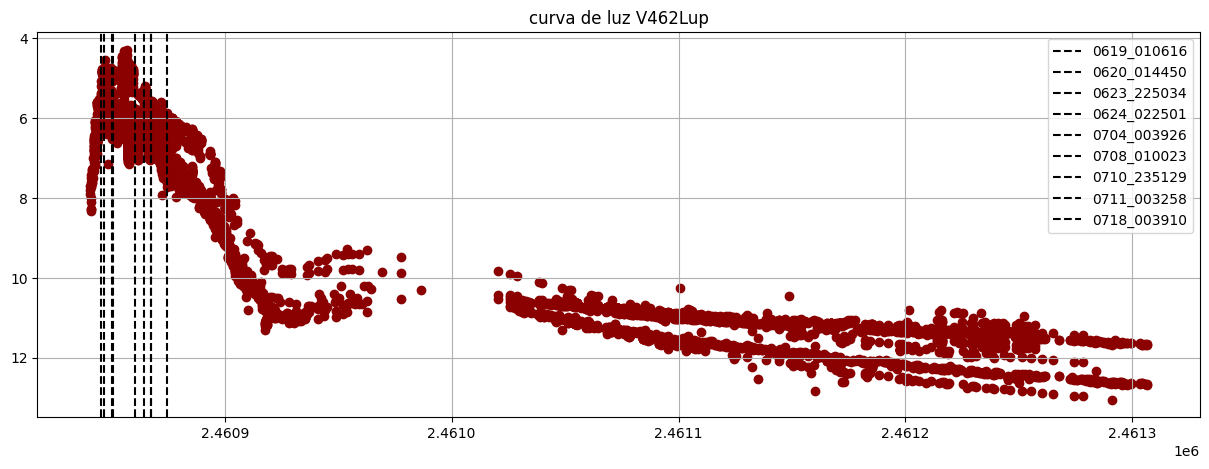

In [35]:
plt.figure(figsize=(15,5))
plt.title('curva de luz V462Lup')
plt.gca().invert_yaxis()
plt.axvline(espectros_jd[0], ls='dashed', color='black', label=espectros_strings[0])
plt.axvline(espectros_jd[3], ls='dashed', color='black', label=espectros_strings[3])
plt.axvline(espectros_jd[5], ls='dashed', color='black', label=espectros_strings[5])
plt.axvline(espectros_jd[7], ls='dashed', color='black', label=espectros_strings[7])
plt.axvline(espectros_jd[8], ls='dashed', color='black', label=espectros_strings[8])
plt.axvline(espectros_jd[23], ls='dashed', color='black', label=espectros_strings[23])
plt.axvline(espectros_jd[25], ls='dashed', color='black', label=espectros_strings[25])
plt.axvline(espectros_jd[26], ls='dashed', color='black', label=espectros_strings[26])
plt.axvline(espectros_jd[28], ls='dashed', color='black', label=espectros_strings[28])
#plt.axhline(min(LC['Magnitude']), label= f'{min(LC['Magnitude'])}')
plt.legend()
plt.grid('on')
plt.scatter(LC['JD'], LC['Magnitude'], color='darkred')
plt.show()

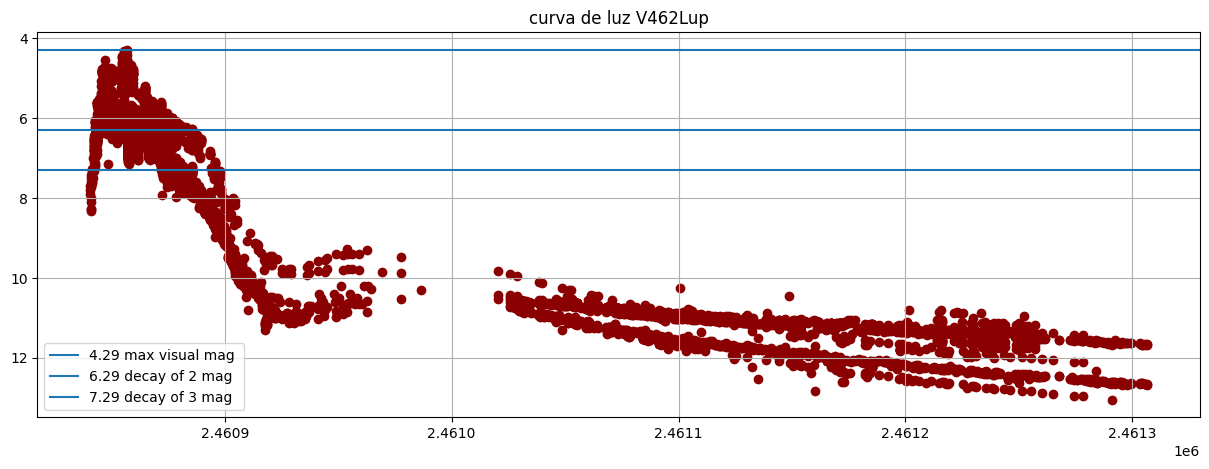

In [42]:
plt.figure(figsize=(15,5))
plt.title('curva de luz V462Lup')
plt.gca().invert_yaxis()
plt.axhline(min(LC['Magnitude']), label= f'{min(LC['Magnitude'])} max visual mag ')
plt.axhline(min(LC['Magnitude']+2), label= f'{min(LC['Magnitude']+2)} decay of 2 mag')
plt.axhline(min(LC['Magnitude']+3), label= f'{min(LC['Magnitude']+3)} decay of 3 mag')
plt.legend()
plt.grid('on')
plt.scatter(LC['JD'], LC['Magnitude'], color='darkred')

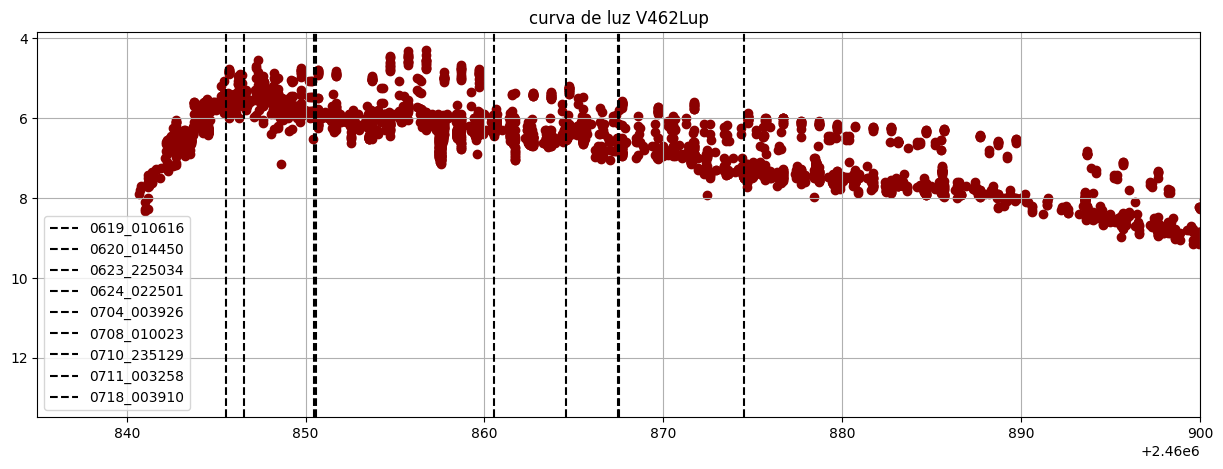

In [46]:
plt.figure(figsize=(15,5))
plt.title('curva de luz V462Lup')
plt.gca().invert_yaxis()
plt.axvline(espectros_jd[0], ls='dashed', color='black', label=espectros_strings[0])
plt.axvline(espectros_jd[3], ls='dashed', color='black', label=espectros_strings[3])
plt.axvline(espectros_jd[5], ls='dashed', color='black', label=espectros_strings[5])
plt.axvline(espectros_jd[7], ls='dashed', color='black', label=espectros_strings[7])
plt.axvline(espectros_jd[8], ls='dashed', color='black', label=espectros_strings[8])
plt.axvline(espectros_jd[23], ls='dashed', color='black', label=espectros_strings[23])
plt.axvline(espectros_jd[25], ls='dashed', color='black', label=espectros_strings[25])
plt.axvline(espectros_jd[26], ls='dashed', color='black', label=espectros_strings[26])
plt.axvline(espectros_jd[28], ls='dashed', color='black', label=espectros_strings[28])
plt.xlim(2.460835*1E6,2.4609*1E6)
plt.legend()
plt.grid('on')
plt.scatter(LC['JD'], LC['Magnitude'], color='darkred')